# Tutorial 05b — Historical OD-flow prediction

Zone demand counts trips starting in each region. OD prediction is harder: it asks how many trips will travel from an origin to a destination next hour. We first map all Manhattan zones, then use the ten busiest zones for the hourly modelling exercise so it remains fast in class. The modelling subset is selected with training-period data only. We keep the target on its raw count scale—`log1p` is not automatically beneficial—and compare five course models after small validation studies.

## Open this notebook

- **Colab.** Open the notebook, then run the setup cell below before any data-loading cell. It clones the public course repository and changes into `05 Transportation Applications I`, so relative data paths work.
- **On your own computer.** Open the notebook from its lesson folder so the data files sit beside it.


In [71]:
from pathlib import Path
import os

def in_colab():
    try:
        import google.colab  # noqa: F401
        return True
    except ImportError:
        return False

if in_colab():
    print("Running in Google Colab")
    REPO_URL = "https://github.com/hku-kejintao/AI-Code.git"
    LESSON_DIR = "05 Transportation Applications I"
    base = Path("/content")
    repo = base / "AI-Code"
    os.chdir(base)
    if not repo.exists():
        !git clone {REPO_URL}
    lesson_path = repo / LESSON_DIR
    if not lesson_path.exists():
        raise FileNotFoundError(f"Lesson folder not found: {lesson_path}")
    os.chdir(lesson_path)
else:
    print("Running on your own computer")

print("Current folder:", os.getcwd())


Running on your own computer
Current folder: /Users/jintaoke/Library/CloudStorage/OneDrive-TheUniversityOfHongKong/courses/AI course slides/course-code/AI-Code/05 Transportation Applications I


### Check the packages

The cell should print version numbers and the word `ready`. NumPy holds arrays, pandas holds tables, Matplotlib draws figures, and scikit-learn provides preprocessing, models, and metrics.


In [72]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print("numpy", np.__version__)
print("pandas", pd.__version__)
print("matplotlib", plt.matplotlib.__version__)
print("scikit-learn", sklearn.__version__)
print("ready")


numpy 1.26.4
pandas 2.2.2
matplotlib 3.8.4
scikit-learn 1.7.2
ready


### Install, only if the check failed

Skip this cell when the check printed `ready`. After installation finishes, restart the kernel and run the cells above again.


In [73]:
%pip install numpy pandas matplotlib scikit-learn


Note: you may need to restart the kernel to use updated packages.


In [74]:
from pathlib import Path
import json,warnings,numpy as np,pandas as pd,matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression,Lasso,Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
warnings.filterwarnings("ignore"); np.random.seed(42)
FAMILY_COLORS={"Linear":"#4C78A8","Lasso":"#F58518","Ridge":"#B279A2","RF":"#54A24B","ANN":"#E45756"}
plt.rcParams.update({"figure.dpi":110,"axes.spines.top":False,"axes.spines.right":False,"axes.titleweight":"bold"})
required=["nyc_od_hour.csv.gz","nyc_od_summary.csv","nyc_zone_features.csv","nyc_taxi_zones.geojson"]
assert all(Path(x).exists() for x in required), "Run from the 05 folder."

hourly modelling shape: (144000, 4) modelling zones: 10 complete Manhattan map zones: 67


,time,origin,destination,flow
0,2024-01-01,161,161,6
1,2024-01-01,161,237,27
2,2024-01-01,161,236,9
3,2024-01-01,161,162,9
4,2024-01-01,161,230,0


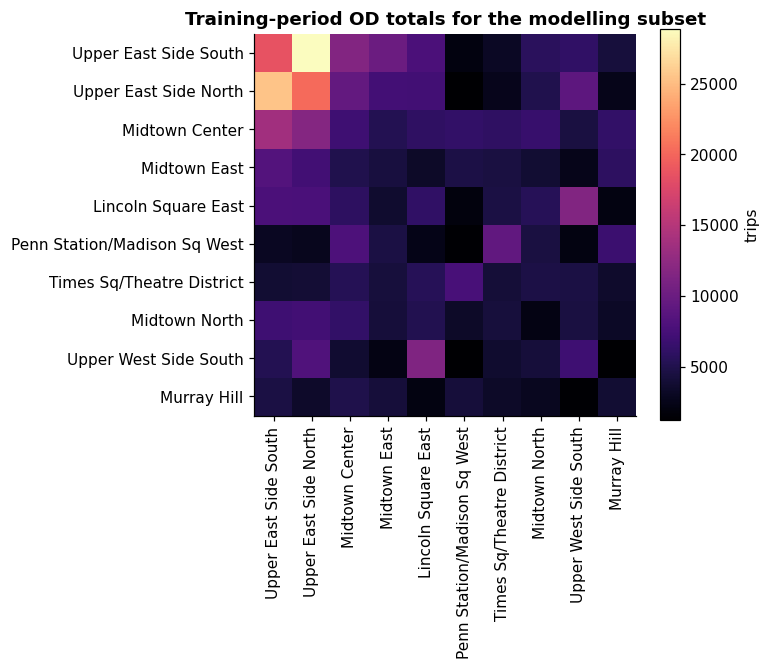

In [75]:
od=pd.read_csv("nyc_od_hour.csv.gz",parse_dates=["time"]); all_od=pd.read_csv("nyc_od_summary.csv"); zones=pd.read_csv("nyc_zone_features.csv"); geo=json.load(open("nyc_taxi_zones.geojson"))
totals=od[od.time<"2024-02-10"].groupby("origin").flow.sum().nlargest(10); ids=totals.index.tolist(); od=od[od.origin.isin(ids)&od.destination.isin(ids)].copy()
names=zones.set_index("LocationID").Zone; print("hourly modelling shape:",od.shape,"modelling zones:",len(ids),"complete Manhattan map zones:",len(zones)); display(od.head())
matrix=od[od.time<"2024-02-10"].groupby(["origin","destination"]).flow.sum().unstack(fill_value=0).reindex(index=ids,columns=ids)
plt.figure(figsize=(7,6)); plt.imshow(matrix,cmap="magma"); plt.colorbar(label="trips"); plt.xticks(range(len(ids)),[names[i] for i in ids],rotation=90); plt.yticks(range(len(ids)),[names[i] for i in ids]); plt.title("Training-period OD totals for the modelling subset"); plt.tight_layout()

In [76]:
def polygons(feature):
    g=feature["geometry"]
    return g["coordinates"] if g["type"]=="MultiPolygon" else [g["coordinates"]]

def zone_map(values, title, cmap="YlGnBu", ax=None, colorbar=True):
    values=pd.Series(values)
    if ax is None: _,ax=plt.subplots(figsize=(8,7))
    norm=plt.Normalize(values.min(), values.max() if values.max()>values.min() else values.min()+1)
    for f in geo["features"]:
        zid=int(f["properties"]["LocationID"]); value=values.get(zid,np.nan)
        color="lightgrey" if pd.isna(value) else plt.colormaps[cmap](norm(value))
        for poly in polygons(f):
            ax.fill(*np.asarray(poly[0]).T,facecolor=color,edgecolor="white",linewidth=.45)
    ax.set_title(title); ax.set_aspect("equal"); ax.axis("off")
    if colorbar: plt.colorbar(plt.cm.ScalarMappable(norm=norm,cmap=cmap),ax=ax,shrink=.7)
    return ax

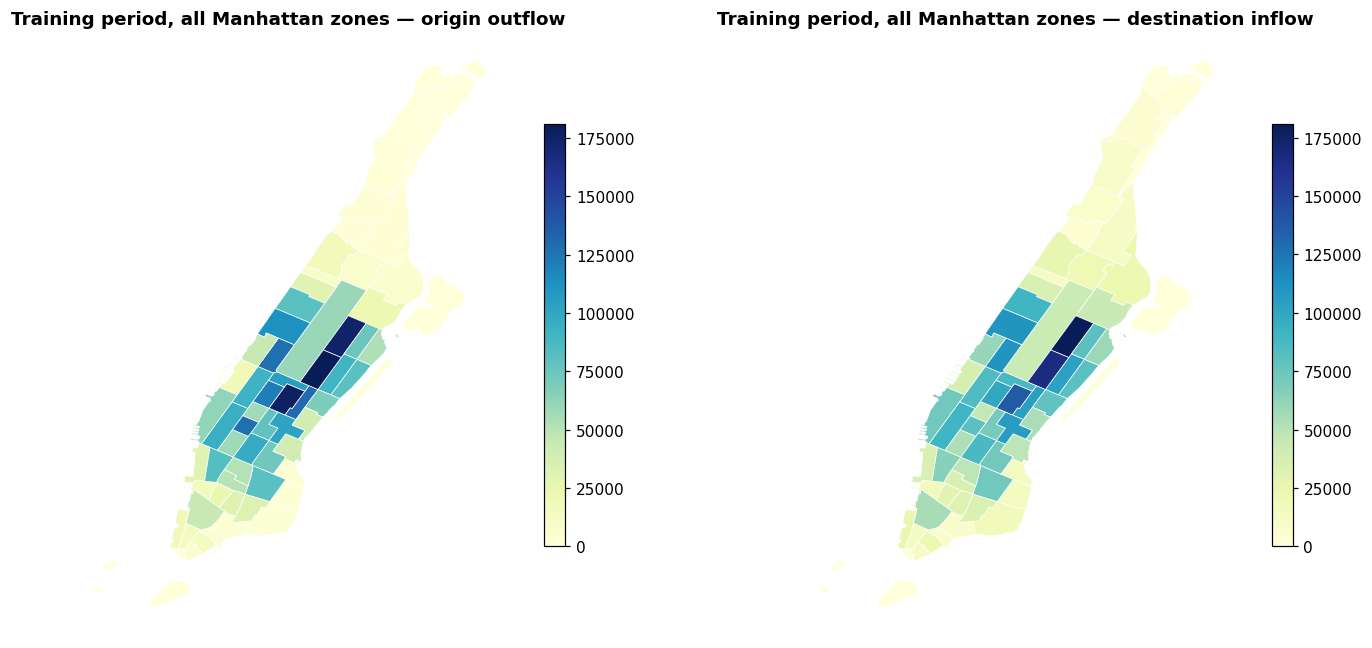

In [77]:
fig,ax=plt.subplots(1,2,figsize=(14,6)); zone_map(all_od.groupby("origin").flow.sum(),"Training period, all Manhattan zones — origin outflow",ax=ax[0]); zone_map(all_od.groupby("destination").flow.sum(),"Training period, all Manhattan zones — destination inflow",ax=ax[1]); plt.tight_layout()

## Feature construction

Every OD pair has its own history. We shift within `(origin, destination)`, then add cyclic calendar variables. This is different from 05a: a busy origin does not imply that every destination from that origin is busy.

In [78]:
d=od.sort_values(["origin","destination","time"]).copy()
for lag in [1,2,3,24,168]: d[f"lag_{lag}"]=d.groupby(["origin","destination"]).flow.shift(lag)
d["hour_sin"]=np.sin(2*np.pi*d.time.dt.hour/24); d["hour_cos"]=np.cos(2*np.pi*d.time.dt.hour/24); d["weekend"]=(d.time.dt.dayofweek>=5).astype(int)
d = d.dropna().reset_index(drop=True)
y = d.flow.to_numpy()
features = ["lag_1", "lag_2", "lag_3", "lag_24", "lag_168", "hour_sin", "hour_cos", "weekend"]
train = d.time < "2024-02-10"
valid = d.time.between("2024-02-10", "2024-02-20", inclusive="left")
test = d.time >= "2024-02-20"

X_train = d.loc[train, features].to_numpy()
y_train = d.loc[train, "flow"].to_numpy()
X_valid = d.loc[valid, features].to_numpy()
y_valid = d.loc[valid, "flow"].to_numpy()
X_test = d.loc[test, features].to_numpy()
y_test = d.loc[test, "flow"].to_numpy()

print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_valid:", X_valid.shape, "y_valid:", y_valid.shape)
print("X_test :", X_test.shape, "y_test :", y_test.shape)
print("Each X row describes one OD pair-hour; y is its target flow.")

X_train: (79200, 8) y_train: (79200,)
X_valid: (24000, 8) y_valid: (24000,)
X_test : (24000, 8) y_test : (24000,)
Each X row describes one OD pair-hour; y is its target flow.


In [79]:
def metrics(y,p):
    return {"MAE":mean_absolute_error(y,p),"RMSE":mean_squared_error(y,p)**.5,
            "R2":r2_score(y,p),"WAPE":np.abs(y-p).sum()/np.maximum(np.abs(y).sum(),1)}

## Tune comparable models on validation

The target remains in trips per hour, so MAE and RMSE keep a direct operational interpretation. Every model receives the same historical and calendar features; validation changes only one compact hyperparameter grid within each family.

,family,setting,validation_MAE
10,ANN,ANN | width=16,2.140990
11,ANN,ANN | width=32,2.147131
1,Lasso,Lasso | alpha=0.01,2.220082
2,Lasso,Lasso | alpha=0.1,2.221580
3,Lasso,Lasso | alpha=1,2.411605
0,Linear,Linear | all,2.220560
8,RF,RF | depth=14,2.169783
9,RF,RF | depth=None,2.187062
7,RF,RF | depth=8,2.217719
6,Ridge,Ridge | alpha=10,2.220536


,family,setting,validation_MAE
10,ANN,ANN | width=16,2.140990
8,RF,RF | depth=14,2.169783
1,Lasso,Lasso | alpha=0.01,2.220082
6,Ridge,Ridge | alpha=10,2.220536
0,Linear,Linear | all,2.220560


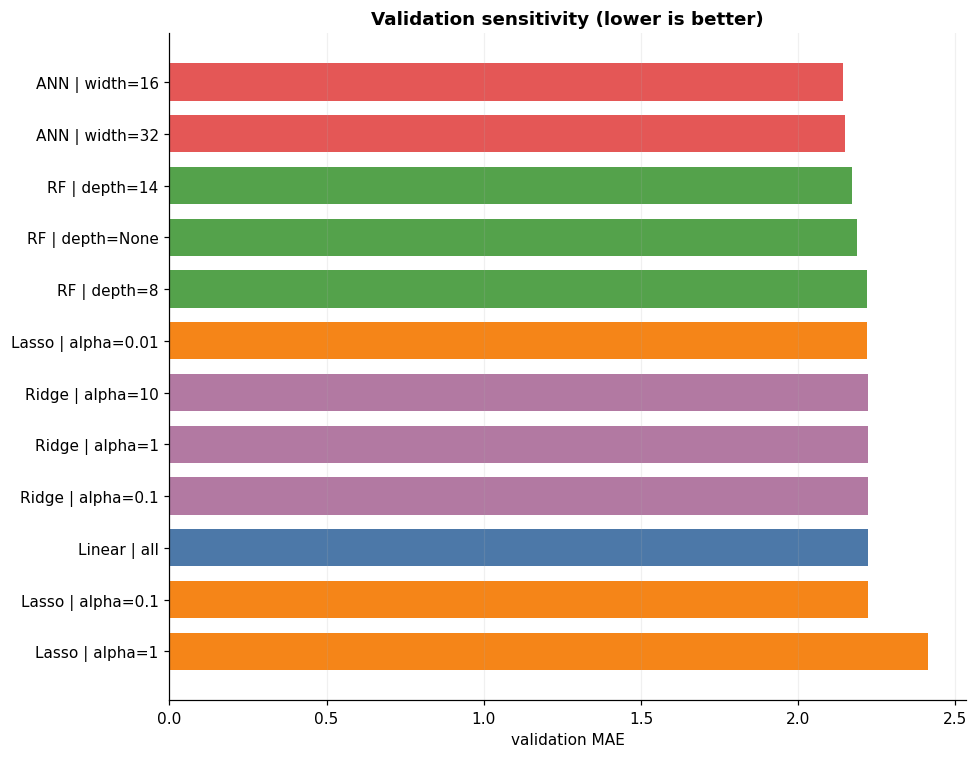

In [80]:
# StandardScaler is used only inside penalised/neural model pipelines.
# It rescales X features with different units; y, predictions, MAE, and RMSE
# remain in the original traffic-flow units shown in the result tables.
candidates={"Linear | all":(LinearRegression(),features)}
for a in [.01,.1,1]: candidates[f"Lasso | alpha={a}"]=(make_pipeline(StandardScaler(),Lasso(alpha=a,max_iter=3000)),features)
for a in [.1,1,10]: candidates[f"Ridge | alpha={a}"]=(make_pipeline(StandardScaler(),Ridge(alpha=a)),features)
for depth in [8,14,None]: candidates[f"RF | depth={depth}"]=(RandomForestRegressor(n_estimators=50,max_depth=depth,min_samples_leaf=3,max_samples=.5,n_jobs=-1,random_state=42),features)
for width in [16,32]: candidates[f"ANN | width={width}"]=(make_pipeline(StandardScaler(),MLPRegressor(hidden_layer_sizes=(width,),max_iter=80,early_stopping=True,random_state=42)),features)
rows=[]
for name,(m,cols) in candidates.items():
    m.fit(d.loc[train,cols],y[train]); p=np.clip(m.predict(d.loc[valid,cols]),0,None); rows.append({"family":name.split(" | ")[0],"setting":name,"validation_MAE":mean_absolute_error(y[valid],p)})
validation=pd.DataFrame(rows); best=validation.loc[validation.groupby("family").validation_MAE.idxmin()].sort_values("validation_MAE"); display(validation.sort_values(["family","validation_MAE"])); display(best)
pv=validation.sort_values("validation_MAE",ascending=False); fig,ax=plt.subplots(figsize=(9,7)); ax.barh(pv.setting,pv.validation_MAE,height=.72,color=pv.family.map(FAMILY_COLORS)); ax.set(xlabel="validation MAE",title="Validation sensitivity (lower is better)"); ax.grid(axis="x",alpha=.18); plt.tight_layout()

## Freeze settings and compare on test

,model,MAE,RMSE,R2,WAPE
0,ANN,2.266170,3.636102,0.839313,0.336273
1,RF,2.271323,3.639989,0.838969,0.337037
2,Lasso,2.340440,3.753783,0.828743,0.347294
4,Linear,2.340917,3.752992,0.828816,0.347364
3,Ridge,2.340921,3.753015,0.828814,0.347365


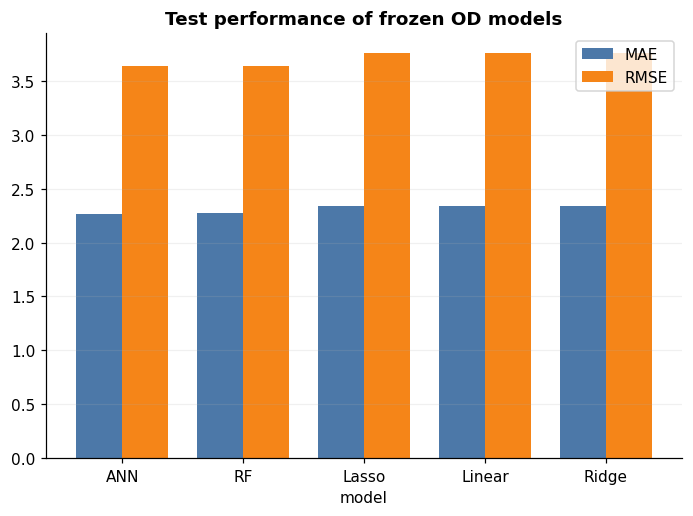

In [81]:
dev=train|valid; preds={}; fitted={}; rows=[]
for _,r in best.iterrows():
    m,cols=candidates[r.setting]; m.fit(d.loc[dev,cols],y[dev]); p=np.clip(m.predict(d.loc[test,cols]),0,None); preds[r.family]=p; fitted[r.family]=(m,cols); rows.append({"model":r.family,**metrics(y[test],p)})
results=pd.DataFrame(rows).sort_values("MAE"); display(results); results.set_index("model")[["MAE","RMSE"]].plot.bar(rot=0,width=.76,color=["#4C78A8","#F58518"],title="Test performance of frozen OD models"); plt.grid(axis="y",alpha=.18); plt.tight_layout()

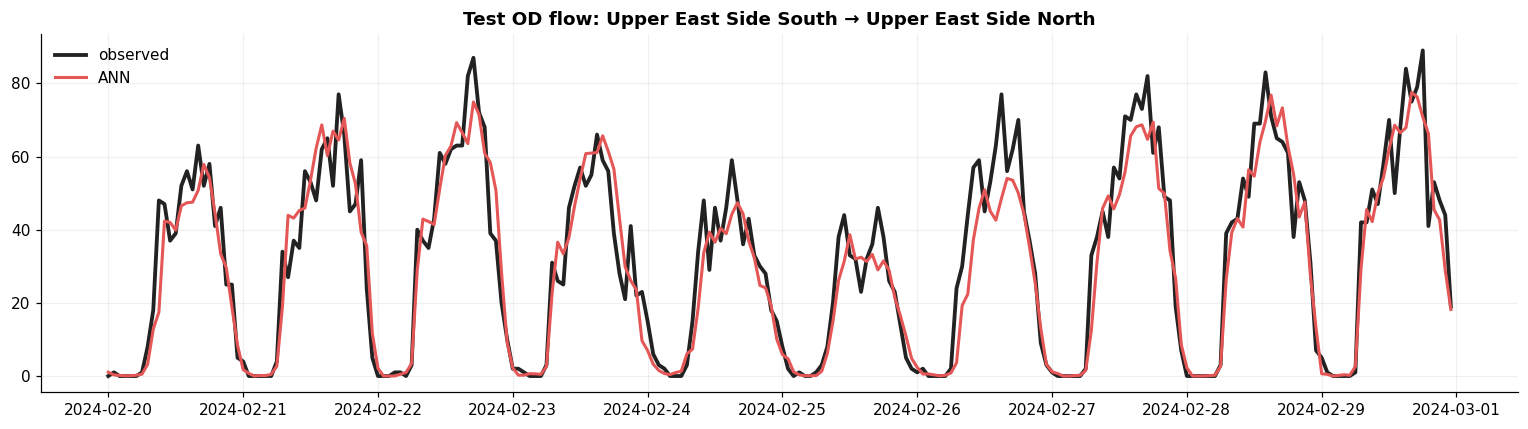

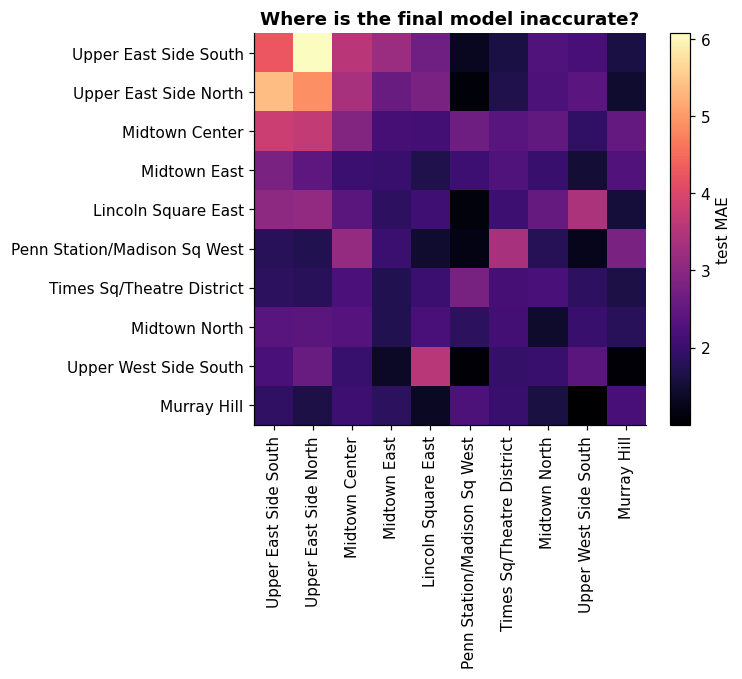

In [82]:
winner=results.iloc[0].model; test_df=d.loc[test,["time","origin","destination"]].copy(); test_df["observed"]=y[test]; test_df["predicted"]=preds[winner]
pair=test_df.groupby(["origin","destination"])["observed"].sum().idxmax(); q=test_df[(test_df.origin==pair[0])&(test_df.destination==pair[1])]
plt.figure(figsize=(14,4)); plt.plot(q.time,q.observed,label="observed",lw=2.5,color="#222222"); plt.plot(q.time,q.predicted,label=winner,color=FAMILY_COLORS[winner],lw=2); plt.title(f"Test OD flow: {names[pair[0]]} → {names[pair[1]]}"); plt.legend(frameon=False); plt.grid(alpha=.18); plt.tight_layout()
err=test_df.assign(ae=lambda x:abs(x.observed-x.predicted)).groupby(["origin","destination"]).ae.mean().unstack().reindex(index=ids,columns=ids)
plt.figure(figsize=(7,6)); plt.imshow(err,cmap="magma"); plt.colorbar(label="test MAE"); plt.xticks(range(len(ids)),[names[i] for i in ids],rotation=90); plt.yticks(range(len(ids)),[names[i] for i in ids]); plt.title("Where is the final model inaccurate?"); plt.tight_layout()

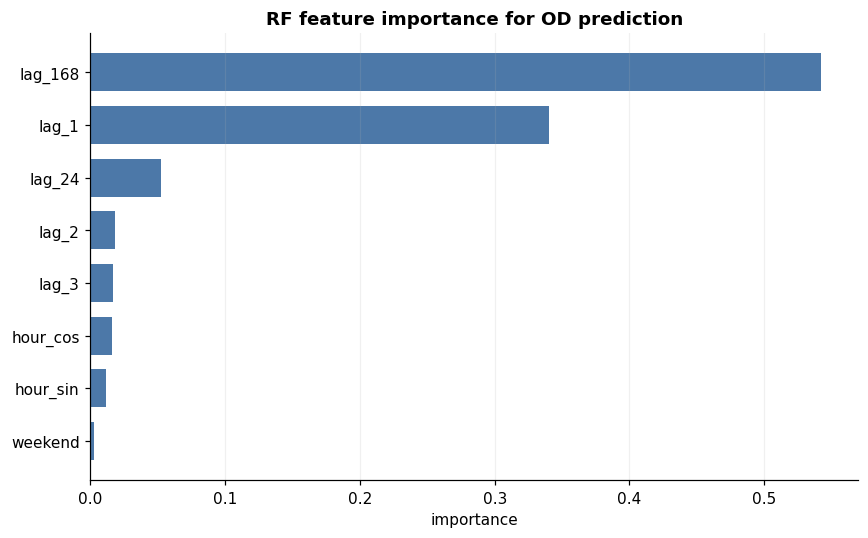

In [83]:
rf,cols=fitted["RF"]; imp=pd.Series(rf.feature_importances_,index=cols).sort_values(); fig,ax=plt.subplots(figsize=(8,5)); ax.barh(imp.index,imp.values,height=.72,color="#4C78A8"); ax.set(xlabel="importance",title="RF feature importance for OD prediction"); ax.grid(axis="x",alpha=.18); plt.tight_layout()